# Investigate the TLE population

Merges a TLE snapshot (file `tle_YYYYMMDD_YYYYMMDD.csv` written by `spacetrack_tle_snapshot.py`
in the folder set in `config.ini`, section `[tle_snapshot]`) with a SATCAT file
(`satcat_YYYYMMDD.csv` written by `spacetrack_satcat.py` in the folder set in section `[satcat]`),
then plots inclination vs semi-major axis for the whole population, LEO and GEO.

In [ ]:
from pathlib import Path
import configparser

import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.gridspec as gridspec

# Constants
MU = 398_600.4418       # Earth gravitational parameter, km³/s²
R_EARTH = 6_378.137     # Earth radius WGS84, km
SEC_PER_DAY = 86_400

TLE_SNAPSHOT = "tle_20261024_20261025.csv"
SATCAT       = "satcat_20260830.csv"

# Folders read from config.ini (same file as spacetrack_tle_snapshot.py and spacetrack_satcat.py)
config = configparser.ConfigParser()
if not config.read("config.ini", encoding="utf-8"):
    raise FileNotFoundError("config.ini not found next to the notebook")
TLE_FILE    = Path(config["tle_snapshot"]["output_dir"]).expanduser() / TLE_SNAPSHOT
SATCAT_FILE = Path(config["satcat"]["output_dir"]).expanduser() / SATCAT
for f in (TLE_FILE, SATCAT_FILE):
    if not f.exists():
        raise FileNotFoundError(f"File not found: {f} (see output_dir in config.ini)")

TOP_N       = 10          # countries shown individually
MIN_PCT     = 0.5         # below this % → merged into "Others"
OUTPUT      = Path("outputs/satcat_piechart.png")
OUTPUT_INC_VS_SMA_ALL = Path("outputs/population_inc_vs_sma_all.png")
OUTPUT_INC_VS_SMA_LEO = Path("outputs/population_inc_vs_sma_leo.png")
OUTPUT_INC_VS_SMA_GEO = Path("outputs/population_inc_vs_sma_geo.png")
OUTPUT_INC_VS_SMA_LEO_PRC = Path("outputs/population_inc_vs_sma_leo_prc.png")
OUTPUT_INC_VS_SMA_GEO_PRC = Path("outputs/population_inc_vs_sma_geo_prc.png")

TYPE_MAP = {
    "PAYLOAD":     ("Satellite",   "#2196F3", 3),
    "DEBRIS":      ("Debris",      "#FF5722", 2),
    "ROCKET BODY": ("Upper Stage", "#4CAF50", 4),
}

FileNotFoundError: File not found: /Users/alexispetit/Documents/TLE_database/tle_20260830_20261025.csv (see output_dir in config.ini)

## Show population

Create a dataframe merging TLE and satcat files

In [ ]:
def parse_tle(path: Path) -> pd.DataFrame:
    raw = pd.read_csv(path, dtype={"norad_id": str})
    records = []
    for row in raw.itertuples(index=False):
        line1 = row.line1.strip()
        line2 = row.line2.strip()
        try:
            sat_id = int(row.norad_id)
        except ValueError:
            continue  # alpha-5 IDs not yet in SATCAT

        ecc     = float("0." + line2[26:33])
        inc     = float(line2[8:16])
        mn      = float(line2[52:63])
        n_rad_s = mn * 2 * math.pi / SEC_PER_DAY
        sma     = (MU / n_rad_s ** 2) ** (1 / 3)

        records.append({
            "NORAD_CAT_ID": sat_id,
            "sma": sma,
            "inc": inc,
            "per": sma * (1 - ecc) - R_EARTH,
            "apo": sma * (1 + ecc) - R_EARTH,
            "line1": line1,
            "line2": line2,
        })

    return pd.DataFrame(records)

def merge(satcat_path: Path, tle_df: pd.DataFrame) -> pd.DataFrame:
    satcat = pd.read_csv(satcat_path)
    df = satcat.merge(tle_df, on="NORAD_CAT_ID", how="inner")
    df = df[df["OBJECT_TYPE"].isin(TYPE_MAP)]   # drop UNKNOWN
    return df

tle_df = parse_tle(TLE_FILE)
population = merge(SATCAT_FILE, tle_df)
print(population.columns)

Index(['INTLDES', 'NORAD_CAT_ID', 'OBJECT_TYPE', 'SATNAME', 'COUNTRY',
       'LAUNCH', 'SITE', 'DECAY', 'PERIOD', 'INCLINATION', 'APOGEE', 'PERIGEE',
       'COMMENT', 'COMMENTCODE', 'RCSVALUE', 'RCS_SIZE', 'FILE', 'LAUNCH_YEAR',
       'LAUNCH_NUM', 'LAUNCH_PIECE', 'CURRENT', 'OBJECT_NAME', 'OBJECT_ID',
       'OBJECT_NUMBER', 'sma', 'inc', 'per', 'apo', 'line1', 'line2'],
      dtype='str')


Saved → outputs/population_inc_vs_sma_all.png
Saved → outputs/population_inc_vs_sma_leo.png
Saved → outputs/population_inc_vs_sma_geo.png


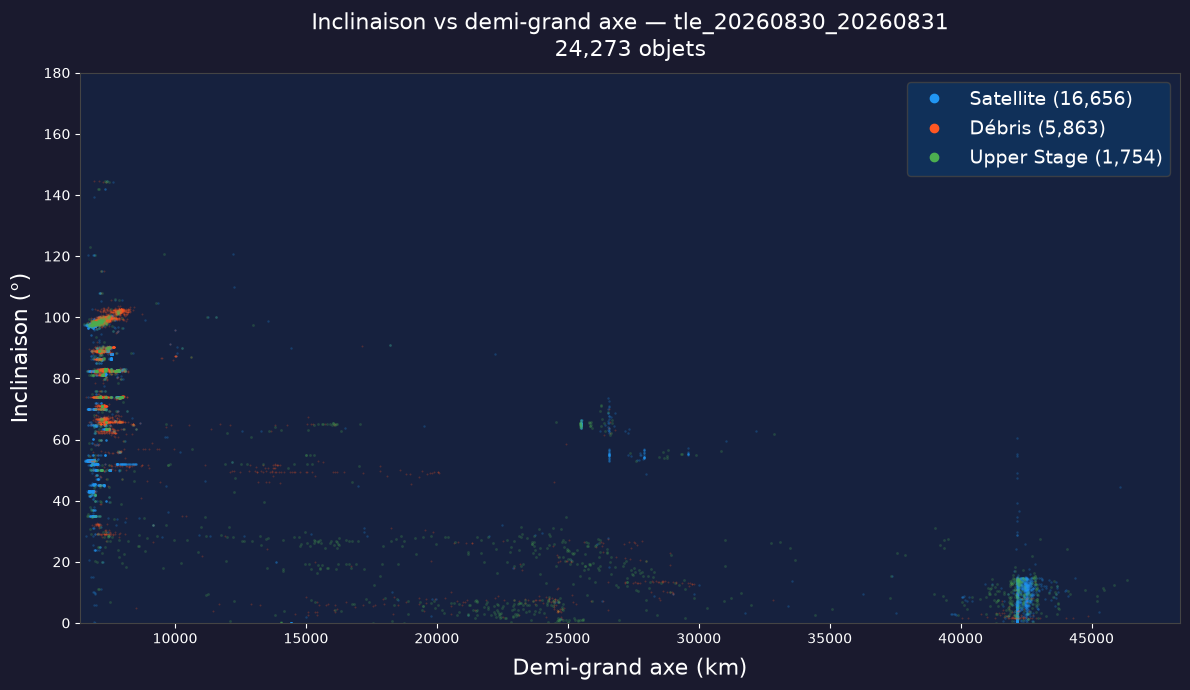

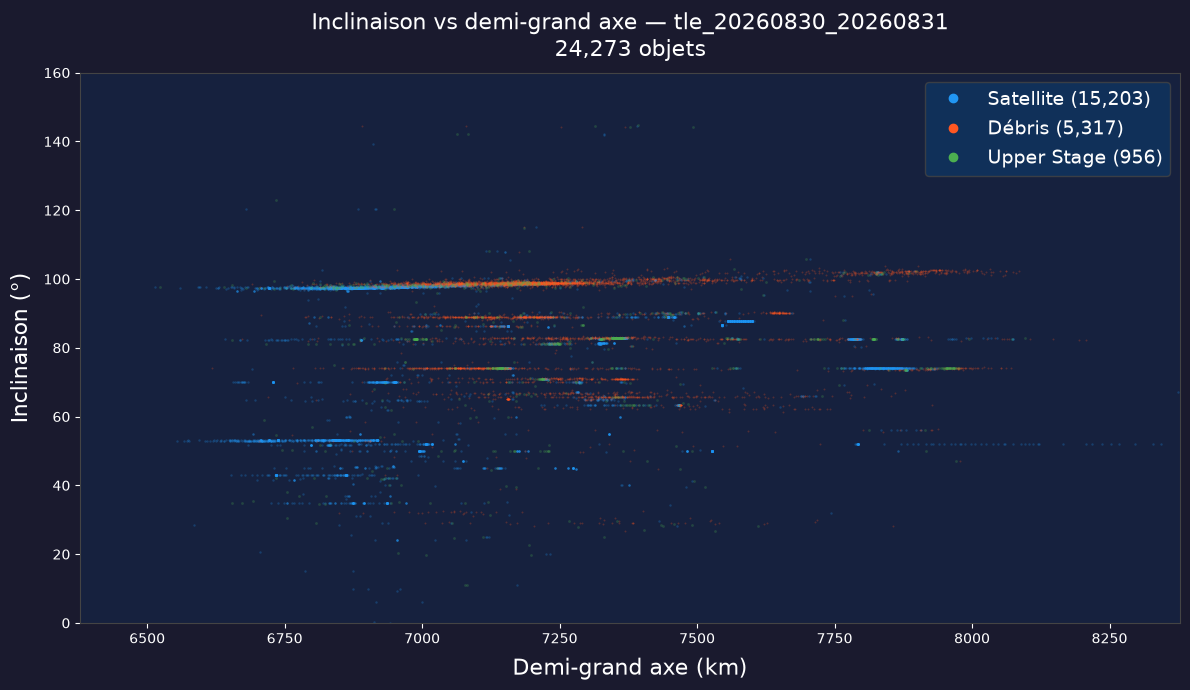

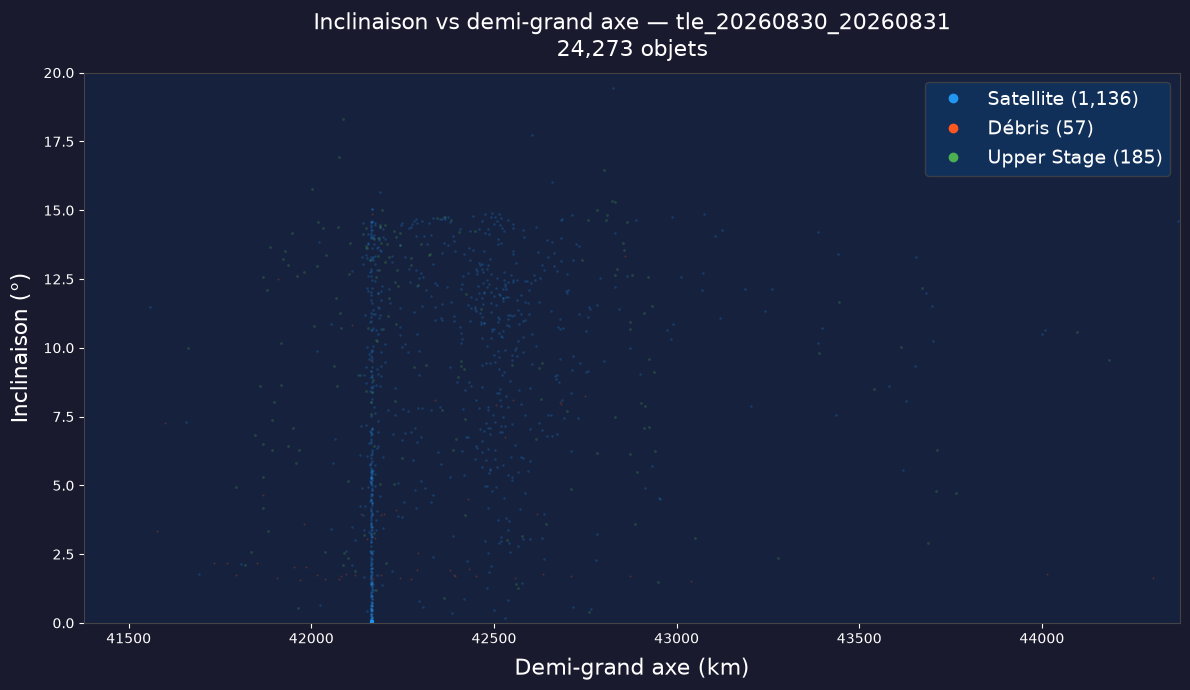

In [ ]:
def leo_filter(df: pd.DataFrame) -> pd.DataFrame:
    return df[(df["apo"] < 2000) & (df["per"] < 2000)]

def geo_filter(df: pd.DataFrame) -> pd.DataFrame:
    return df[(df["apo"] < 42000) & (df["per"] > 35000 )]

def plot_inc_vs_sma(df: pd.DataFrame, output: Path, region: str) -> None:
    fig, ax = plt.subplots(figsize=(12, 7))
    fig.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#16213e")

    if region=='LEO':
        filtered_df = leo_filter(df)
    elif region=='GEO':
        filtered_df = geo_filter(df)
    else:
        filtered_df = df

    legend_handles = []

    for obj_type, (label, color, size) in TYPE_MAP.items():
        sub = filtered_df[filtered_df["OBJECT_TYPE"] == obj_type]
        ax.scatter(
            sub["sma"], sub["inc"],
            s=size, color=color, alpha=0.25,
            linewidths=0, rasterized=True,
        )
        legend_handles.append(
            mlines.Line2D([], [], color=color, marker="o", linestyle="None",
                          markersize=6, label=f"{label} ({len(sub):,})")
        )

    # Reference orbits
    #for name, alt in [("LEO 500 km", 500), ("GEO", 35_786)]:
    #    ax.axvline(R_EARTH + alt, color="white", linewidth=0.6,
    #               linestyle="--", alpha=0.4)
    #    ax.text(R_EARTH + alt + 60, 175, name,
    #            color="white", fontsize=7, alpha=0.6)

    ax.set_xlabel("Semi-major axis (km)", color="white", labelpad=8,fontsize=16)
    ax.set_ylabel("Inclination (°)", color="white", labelpad=8,fontsize=16)
    ax.set_title(
        f"Inclination vs semi-major axis — {TLE_FILE.stem}\n"
        f"{len(df):,} objects",
        color="white", fontsize=16, pad=12,
    )

    if region=='LEO':
        ax.set_xlim(R_EARTH, R_EARTH+2E3)
        ax.set_ylim(0, 160)
    elif region=='GEO':
        ax.set_xlim(R_EARTH+35E3, R_EARTH+38E3)
        ax.set_ylim(0, 20)
    else:
        ax.set_xlim(R_EARTH, R_EARTH+42E3)
        ax.set_ylim(0, 180)

    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_edgecolor("#444")

    ax.legend(
        handles=legend_handles,
        facecolor="#0f3460", edgecolor="#444",
        labelcolor="white", fontsize=14,
        loc="upper right",
    )

    fig.tight_layout()
    fig.savefig(output, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved → {output}")

plot_inc_vs_sma(population, OUTPUT_INC_VS_SMA_ALL, 'ALL')
plot_inc_vs_sma(population, OUTPUT_INC_VS_SMA_LEO, 'LEO')
plot_inc_vs_sma(population, OUTPUT_INC_VS_SMA_GEO, 'GEO')

## Chinese population (PRC)

Filters the population on `COUNTRY == "PRC"`, then reuses the same inclination vs semi-major axis plots, first in low Earth orbit (LEO), then in geostationary orbit (GEO).

In [ ]:
population_prc = population[population["COUNTRY"] == "PRC"]
population_prc_leo = leo_filter(population_prc)
population_prc_geo = geo_filter(population_prc)

print(f"Chinese objects (total) : {len(population_prc):,}")
print(f"Chinese objects in LEO  : {len(population_prc_leo):,}")
print(population_prc_leo.groupby("OBJECT_TYPE").size().sort_values(ascending=False).to_string())
print()
print(f"Chinese objects in GEO  : {len(population_prc_geo):,}")
print(population_prc_geo.groupby("OBJECT_TYPE").size().sort_values(ascending=False).to_string())

Chinese objects (total) : 3,603
Chinese objects in LEO  : 3,373
OBJECT_TYPE
DEBRIS         2178
PAYLOAD        1021
ROCKET BODY     174

Chinese objects in GEO  : 128
OBJECT_TYPE
PAYLOAD        113
ROCKET BODY     14
DEBRIS           1


Saved → outputs/population_inc_vs_sma_leo_prc.png
Saved → outputs/population_inc_vs_sma_geo_prc.png


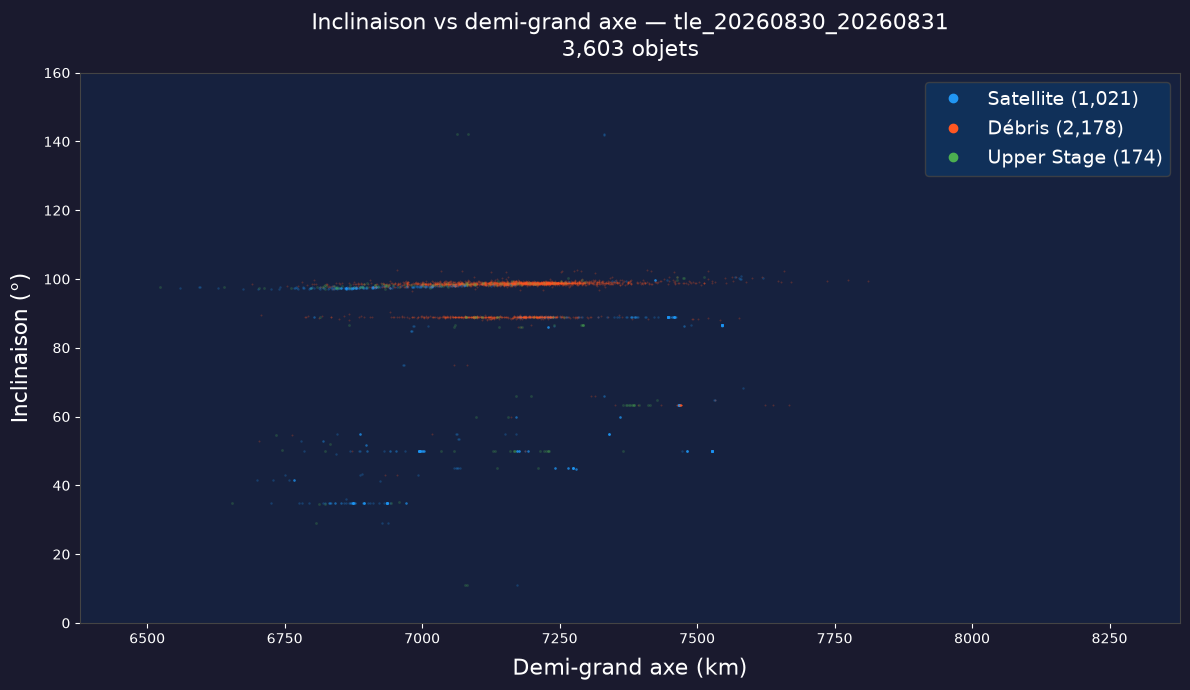

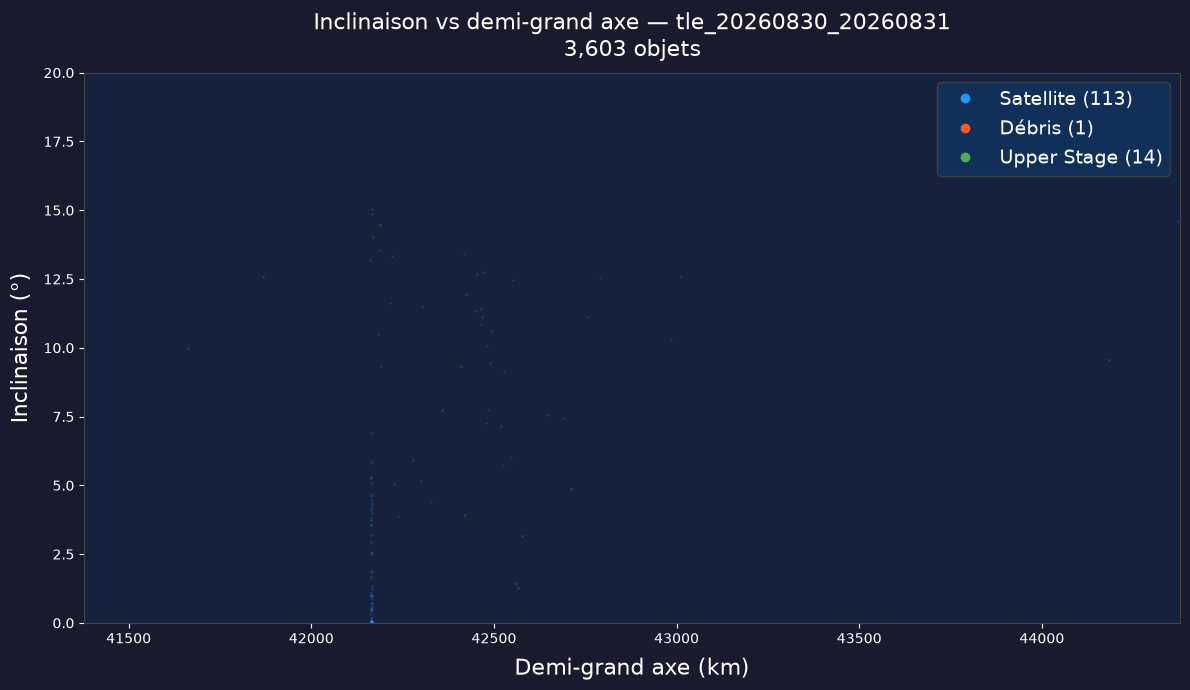

In [ ]:
plot_inc_vs_sma(population_prc, OUTPUT_INC_VS_SMA_LEO_PRC, 'LEO')
plot_inc_vs_sma(population_prc, OUTPUT_INC_VS_SMA_GEO_PRC, 'GEO')